<a href="https://colab.research.google.com/github/lara-ms/Aula-M06/blob/main/ATV_12_Lara_Siecola.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Nome: Lara Moreira Siécola
## Matricula: 2365
-----


# **ATV 12 — Organização de Dados**

Esta atividade pratica a **organização e a apresentação de dados** em Estatística: classificação de variáveis, distribuições de frequências (qualitativas, quantitativas discretas e contínuas agrupadas em classes), representações gráficas e tabelas de contingência.

**Objetivos**
- Classificar variáveis (tipo e escala de medida).
- Construir **tabelas de frequências** (fi, fr, fr%, Fac, xi) para cada tipo de variável.
- Agrupar dados contínuos em classes (regra de **Sturges**, amplitude, intervalo de classe).
- Construir **gráficos** adequados: barras, setores, bastões, histograma, polígono de frequências.


## Instruções gerais

- Execute as células na ordem em que aparecem.
- Sempre **identifique o tipo da variável** antes de escolher a tabela e o gráfico.
- Ferramentas úteis:
  - `Series.value_counts()` → frequências absolutas (`sort_index()` para ordenar pelos valores);
  - `Series.cumsum()` → frequências acumuladas;
  - `plt.bar`, `plt.pie`, `plt.stem`, `plt.step` → gráficos.


In [31]:
# Imports úteis para toda a atividade
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.precision", 4)



## Exercício 1 — **Classificação de variáveis** (tipo e escala)

**Contexto**: Um hospital registra, para cada paciente atendido, as variáveis abaixo.

| # | **Variável**                                         | **Exemplo de valor**        |
|:-:|------------------------------------------------------|-----------------------------|
| 1 | Sexo                                                 | F                           |
| 2 | Tipo sanguíneo                                       | AB                          |
| 3 | Grau de escolaridade (fundamental, médio, superior)  | Médio                       |
| 4 | Número de filhos                                     | 2                           |
| 5 | Altura (cm)                                          | 168,5                       |
| 6 | Temperatura corporal (°C)                            | 36,8                        |
| 7 | Satisfação (ruim, regular, boa, ótima)               | Boa                         |
| 8 | Número de internações nos últimos 5 anos             | 0                           |
| 9 | Estado civil                                         | Casado(a)                   |
| 10 | Tempo de espera no pronto-atendimento (min)         | 37                          |

1. Classifique cada variável como **qualitativa nominal**, **qualitativa ordinal**, **quantitativa discreta** ou **quantitativa contínua**.
2. Informe a **escala de medida** de cada uma (nominal, ordinal, intervalar ou razão).
3. Organize a classificação em um `DataFrame` (colunas *Tipo* e *Escala*).
4. Conte quantas variáveis há em cada tipo.


In [32]:
dados_paciente = [
    ("Sexo", "Qualitativa Nominal", "Nominal"),
    ("Tipo sanguíneo", "Qualitativa Nominal", "Nominal"),
    ("Grau de escolaridade", "Qualitativa Ordinal", "Ordinal"),
    ("Número de filhos", "Quantitativa Discreta", "Razão"),
    ("Altura (cm)", "Quantitativa Contínua", "Razão"),
    ("Temperatura corporal (°C)", "Quantitativa Contínua", "Intervalar"),
    ("Satisfação", "Qualitativa Ordinal", "Ordinal"),
    ("Número de internações", "Quantitativa Discreta", "Razão"),
    ("Estado civil", "Qualitativa Nominal", "Nominal"),
    ("Tempo de espera (min)", "Quantitativa Contínua", "Razão")
]

# colocando no dataframe
df_dados = pd.DataFrame(dados_paciente, columns=["Variável", "Tipo", "Escala"])
display(df_dados)

# contando quantas variaveis há em cada tipo
print("Quantidade de variáveis por tipo:")
display(df_dados["Tipo"].value_counts())

,Variável,Tipo,Escala
0,Sexo,Qualitativa Nominal,Nominal
1,Tipo sanguíneo,Qualitativa Nominal,Nominal
2,Grau de escolaridade,Qualitativa Ordinal,Ordinal
3,Número de filhos,Quantitativa Discreta,Razão
4,Altura (cm),Quantitativa Contínua,Razão
5,Temperatura corporal (°C),Quantitativa Contínua,Intervalar
6,Satisfação,Qualitativa Ordinal,Ordinal
7,Número de internações,Quantitativa Discreta,Razão
8,Estado civil,Qualitativa Nominal,Nominal
9,Tempo de espera (min),Quantitativa Contínua,Razão


Quantidade de variáveis por tipo:


,count
Tipo,
Qualitativa Nominal,3
Quantitativa Contínua,3
Qualitativa Ordinal,2
Quantitativa Discreta,2


**Conclusão:**

1.2.**Classificando** cada variável e informando *escala*
- sexo : **qualitativa nominal** / *nominal*
- tipo sanguineo : **qualitativa nominal** / *nominal*
- grau de escolaridade : **qualitativa ordinal** / *ordinal*
- numero de filhos : **quantitativa discreta** / *razão*
- altura : **quantitativa continua** / *razão*
- temperatura corporal : **quantitativa continua** / *intervalar*
- satisfação : **qualitativa ordinal** / *ordinal*
- numero de internações : **quantitativa discreta** / *razão*
- estado civil : **qualitativa nominal** / *nominal*
- tempo de espera : **quantitativa continua** / *razão*

4.**Quantidade** em cada tipo:
- qualitativa nominal : 3
- qualitativa ordinal : 2
- quantitativa discreta : 2
- quantitativa continua : 3






## Exercício 2 — Distribuição de frequências de uma variável **qualitativa**

**Contexto**: Em uma campanha de doação, foi registrado o **tipo sanguíneo** de **n = 40** doadores. Os dados brutos estão na célula abaixo.

1. Identifique o tipo e a escala da variável.
2. Construa a **tabela de frequências** com **fi**, **fr** e **fr (%)**, ordenada de forma decrescente por fi.
3. Verifique que Σfi = n e Σfr = 1.
4. Construa um **gráfico de barras** (fi) e um **gráfico de setores** (%).
5. Indique a **moda** e conclua.


In [33]:
# Dados brutos — tipo sanguíneo de 40 doadores
sangue = pd.Series([
    'O', 'A', 'O', 'O', 'A', 'A', 'O', 'B', 'O', 'B',
    'O', 'O', 'O', 'B', 'AB', 'O', 'A', 'O', 'O', 'A',
    'O', 'B', 'O', 'B', 'A', 'A', 'A', 'AB', 'AB', 'O',
    'A', 'O', 'A', 'A', 'A', 'O', 'A', 'B', 'A', 'O'
], name="Tipo sanguíneo")


,fi,fr,fr (%)
Tipo sanguíneo,,,
A,14,0.350,35.0
AB,3,0.075,7.5
B,6,0.150,15.0
O,17,0.425,42.5


--------------------------------------------------
Σfi: 40
Σfr: 1.0
--------------------------------------------------


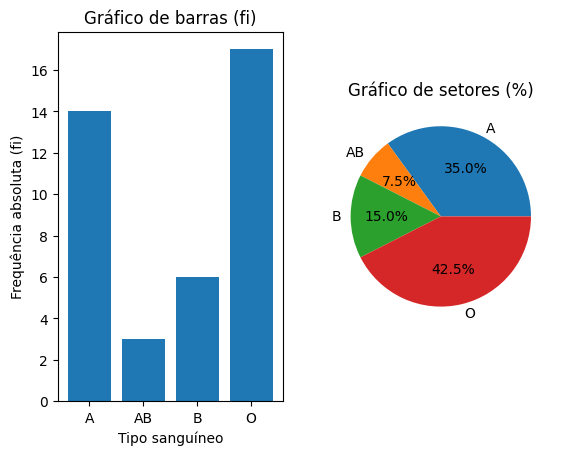

--------------------------------------------------
Moda: 0    O
Name: Tipo sanguíneo, dtype: object


In [34]:
# contruindo tabela de frequencias ---------------------------------------------
fi = sangue.value_counts().sort_index()
fr = fi / fi.sum()
fr_porcentagem = fr * 100

tabela_sangue = pd.DataFrame({
    'fi': fi,
    'fr': fr,
    'fr (%)': fr_porcentagem
})
# print(len(sangue)) # era so para verificar se tava dando certo
display(tabela_sangue)

print('-'*50)
# verificando que Σfi = n e Σfr = 1 --------------------------------------------
print("Σfi:", tabela_sangue['fi'].sum())
print("Σfr:", tabela_sangue['fr'].sum())

print('-'*50)
# plotando os graficos ---------------------------------------------------------
plt.subplot(1, 2, 1)
plt.bar(tabela_sangue.index, tabela_sangue['fi'])
plt.title('Gráfico de barras (fi)')
plt.xlabel('Tipo sanguíneo')
plt.ylabel('Frequência absoluta (fi)')

plt.subplot(1, 2, 2)
plt.pie(tabela_sangue['fr'], labels=tabela_sangue.index, autopct='%1.1f%%')
plt.title('Gráfico de setores (%)')

plt.show()

print('-'*50)
# moda -------------------------------------------------------------------------
moda = sangue.mode()
print("Moda:", moda)

**Conclusão:**

1.Identificando o **tipo** e a *escala* : variável **qualitativa nominal**, escala *nominal*


5.O tipo sanguineo mais frequente é o tipo O representando 35% dos sangues doados.


## Exercício 3 — Distribuição de frequências de uma variável **quantitativa discreta**

**Contexto**: Registrou-se o **número de consultas** realizadas em 12 meses por **n = 30** pacientes de uma unidade de saúde (dados brutos abaixo).

1. Construa a tabela com **fi**, **fr**, **fr (%)**, **Fac** (frequência acumulada) e **Fac (%)**.
2. Construa um **gráfico de bastões** (fi) e um **gráfico em degraus** da frequência acumulada.
3. Responda: (a) Qual é a **moda**? (b) Quantos pacientes (e que %) fizeram **no máximo 2** consultas? (c) Qual a % que fez **4 ou mais**?


In [35]:
# Dados brutos — nº de consultas em 12 meses (30 pacientes)
consultas = pd.Series([
    5, 0, 3, 3, 2, 2, 4, 2, 2, 6, 0, 4, 1, 4, 1,
    1, 2, 1, 0, 5, 4, 1, 3, 2, 3, 3, 1, 2, 2, 3
], name="Consultas")


,fi,fr,fr (%),Fac,Fac (%)
Consultas,,,,,
0,3,0.1000,10.0000,3,10.0000
1,6,0.2000,20.0000,9,30.0000
2,8,0.2667,26.6667,17,56.6667
3,6,0.2000,20.0000,23,76.6667
4,4,0.1333,13.3333,27,90.0000
5,2,0.0667,6.6667,29,96.6667
6,1,0.0333,3.3333,30,100.0000


--------------------------------------------------


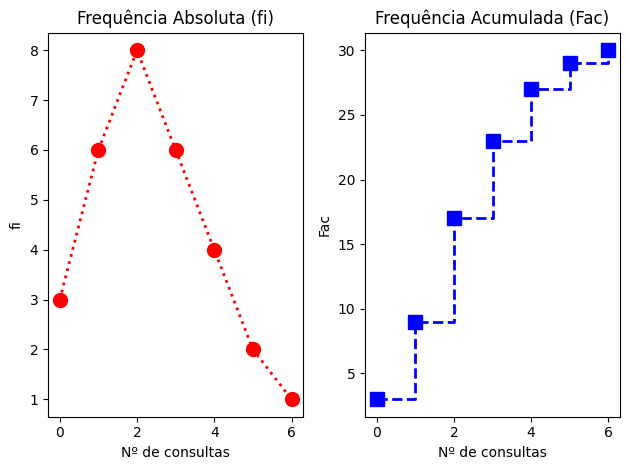

--------------------------------------------------
2 pacientes
17 pacientes 56.67% 
7 pacientes 23.33%


In [36]:
# contruindo tabela ------------------------------------------------------------
fi = consultas.value_counts().sort_index()
fr = consultas.value_counts(normalize=True).sort_index()
fr_por_ac = fr * 100
fac = fi.cumsum()
fac_porcentagem = (fac / len(consultas)) * 100

tabela_consultas = pd.DataFrame({
    'fi': fi,
    'fr': fr,
    'fr (%)': fr_por_ac,
    'Fac': fac,
    'Fac (%)': fac_porcentagem
})
display(tabela_consultas)

print('-'*50)
# plotando graficos ------------------------------------------------------------
plt.subplot(1, 2, 1)
plt.plot(fi.index, fi.values, 'o:r', linewidth=2, markersize=10)
plt.title('Frequência Absoluta (fi)')
plt.xlabel('Nº de consultas')
plt.ylabel('fi')

plt.subplot(1, 2, 2)
plt.plot(fac.index, fac.values, 's--b', linewidth=2, markersize=10, drawstyle='steps-post')
plt.title('Frequência Acumulada (Fac)')
plt.xlabel('Nº de consultas')
plt.ylabel('Fac')

plt.tight_layout()
plt.show()

print('-'*50)
# so para testar se esta certo as respostas
moda_consultas = fi.idxmax()
print(f"{moda_consultas} pacientes")

pacientes_ate_2 = fac.loc[2]
porcentagem_ate_2 = fac_porcentagem.loc[2]
print(f"{pacientes_ate_2} pacientes {porcentagem_ate_2:.2f}% ")

pacientes_4_mais = tabela_consultas.loc[tabela_consultas.index >= 4, 'fi'].sum()
porcentagem_4_mais = tabela_consultas.loc[tabela_consultas.index >= 4, 'fr (%)'].sum()
print(f"{pacientes_4_mais} pacientes {porcentagem_4_mais:.2f}%")

**Conclusão:**

(a) Moda : 2 consultas (tem o fi maior)

(b) Maximo de 2 consultas : 17 (56.7%)  (Fac e Fac % no 2)

(c) 4 ou mais consultas : 23.3% dos pacientes (100% - 76.7%)